# 4.3 Day-ahead and balancing market outcomes

*Analysis notebook for Section 4.3 of the manuscript.*

This section compares each with-actor run against its own baseline
(same pathway, same year, no industrial actors). The study uses the
**price-taker treatment**: each industrial actor bids its FLEXIMOD
volume at a near-cap price (3 000 EUR/MWh for demand, 9 999 EUR/MWh
for aFRR-neg), so every submitted MWh clears whenever the market can
accommodate it. The three questions reported here are:

1. **Day-ahead prices** — how the hourly DA clearing price shifts
   and how the distribution of hourly prices changes.
2. **Negative-aFRR energy market** — price shift and industrial
   accepted volume relative to the ≈ 1 800 MW system requirement.
3. **Aggregate market effect per behavioural case** — a summary table
   across the six pathways and four milestone years.

The price-setter (`_BID`) runs produced during model development are
not reported here; their role was limited to a sensitivity check and
is noted in Section 5.

All inputs come from `actor_impact_utils` (aiu). Case and pathway
labels are those of `aiu.case_label()` and `aiu.pathway_label()`.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

sys.path.insert(0, str(Path.cwd()))
import actor_impact_utils as aiu

from matplotlib import font_manager as fm
for f in Path("/usr/share/fonts/truetype/liberation").glob("LiberationSans-*.ttf"):
    fm.fontManager.addfont(str(f))
sns.set_theme(context="paper", style="whitegrid", font="Liberation Sans")
mpl.rcParams.update({
    "font.size": 7.8, "axes.titlesize": 8.5, "axes.labelsize": 7.8,
    "xtick.labelsize": 7.2, "ytick.labelsize": 7.2, "legend.fontsize": 7.2,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DDDDDD", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
    "mathtext.default": "regular",
})
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

# Okabe-Ito colorblind-safe, one hue per behavioural case (fixed order).
CASE_COLOR = dict(zip(
    aiu.PRICE_TAKER_CASES,
    ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"],
))
print("matplotlib", mpl.__version__, "| seaborn", sns.__version__)

matplotlib 3.11.1 | seaborn 0.13.2


## 4.3.1 Data assembly

The three aiu panel builders give the paper's market view:

- `build_price_panel` — hourly DA and `CRM_energy_neg` prices with vs. baseline.
- `build_afrr_energy_panel` — hourly `CRM_energy_pos` / `CRM_energy_neg` prices with vs. baseline.
- `build_energy_neg_share_panel` — hourly system-wide aFRR-neg accepted volume
   and the share attributed to each sector.

Each panel is cached under `examples/outputs/_analysis_cache/`, so a re-run
from a cold start takes a few minutes at most. The **price-setter
(`_BID`) scenarios are filtered out** immediately after loading so every
subsequent cell operates on the price-taker runs only.

In [2]:
archives = aiu.discover_archives()
archives_pt = archives[~archives["is_bid"]].copy()
print(f"{len(archives)}/384 with-actor scenarios finished "
      f"(price-taker: {len(archives_pt)}, price-setter: {len(archives)-len(archives_pt)} — dropped).")

price_panel  = aiu.build_price_panel(archives)
afrr_energy_panel = aiu.build_afrr_energy_panel(archives)
share_panel  = aiu.build_energy_neg_share_panel(archives)

# Drop price-setter rows across every panel.
price_panel       = price_panel[~price_panel["is_bid"]].copy()
afrr_energy_panel = afrr_energy_panel[~afrr_energy_panel["is_bid"]].copy()
share_panel       = share_panel[~share_panel["case"].str.endswith("_BID")].copy()
print(f"PT-only shapes: price_panel {price_panel.shape} | "
      f"afrr_energy_panel {afrr_energy_panel.shape} | share_panel {share_panel.shape}")

384/384 with-actor scenarios finished (price-taker: 192, price-setter: 192 — dropped).


PT-only shapes: price_panel (3354624, 9) | afrr_energy_panel (3354624, 9) | share_panel (1606014, 9)


## 4.3.2 Day-ahead price impact

**Figure 4.3** — Panel (a): distribution of hourly DA price delta
(*with industrial actors − no-actor baseline*, i.e. the change from
the pathway's own baseline run without any industrial actors) for each
behavioural case. Panel (b): price-duration curves (hours sorted from
highest to lowest price) for one illustrative case, to show the
mechanism — how the demand bids lift the right tail of the baseline
duration curve.

Panel (a) uses 95.3% of 1,677,312 hourly rows (middle band); extreme-cap outliers filtered out.


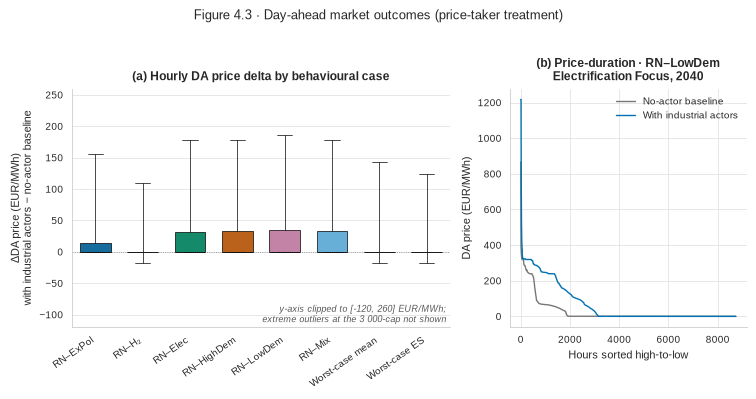

In [3]:
# Panel (a): DA-only, one row per (case, pathway, year, hour).
eom = price_panel[price_panel.market_id == "EOM"].copy()
eom["case_label"] = eom["case"].map(aiu.case_label)
eom["case_order"] = eom["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
eom = eom.sort_values("case_order")

# Panel (b): price-duration curve for one scenario — RN-LowDem fokusstrom 2040
# (the case with the largest sectoral demand, see Fig 4.2a).
PD_CASE, PD_FAM, PD_YR = "NachfrageNiedrig_RN", "fokusstrom", 2040
pd_arch = archives_pt[(archives_pt.case == PD_CASE) & (archives_pt.family == PD_FAM) &
                      (archives_pt.year == PD_YR)].iloc[0]
pd_base = aiu.load_baseline_price(PD_FAM, PD_YR)
pd_actor = aiu.load_actor_price(PD_CASE, PD_FAM, PD_YR, pd_arch.path)

def _dur(d, label):
    d = d[d.market_id == "EOM"].sort_values("price", ascending=False).reset_index(drop=True)
    d["hour_rank"] = d.index + 1
    d["series"] = label
    return d[["hour_rank","price","series"]]

pd_curve = pd.concat([
    _dur(pd_base,  "No-actor baseline"),
    _dur(pd_actor, "With industrial actors"),
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.8), gridspec_kw={"width_ratios":[1.6,1.0]})

# Panel (a) — boxplot of DA delta per case.  Focus on the central 98 % of hours
# so the boxes are visible; the ±3000 outliers at the price cap are filtered out.
eom_show = eom[eom["delta"].between(-120, 260)].copy()
print(f"Panel (a) uses {len(eom_show)/len(eom):.1%} of {len(eom):,} hourly rows "
      "(middle band); extreme-cap outliers filtered out.")
palette_order = [CASE_COLOR[c] for c in aiu.PRICE_TAKER_CASES]
sns.boxplot(data=eom_show, x="case_label", y="delta",
             whis=(5, 95), showfliers=False,
             palette=palette_order,
             order=[aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
             width=0.65, linewidth=0.5, ax=axes[0])
axes[0].axhline(0, color="#888", lw=0.6, ls=":")
axes[0].set_ylim(-120, 260)
axes[0].text(0.99, 0.01,
             "y-axis clipped to [-120, 260] EUR/MWh;\nextreme outliers at the 3 000-cap not shown",
             transform=axes[0].transAxes, ha="right", va="bottom",
             fontsize=6.3, color="#555", style="italic")
axes[0].set_xlabel("")
axes[0].set_ylabel("ΔDA price (EUR/MWh)\nwith industrial actors − no-actor baseline")
axes[0].set_title("(a) Hourly DA price delta by behavioural case", fontweight="bold")
axes[0].tick_params(axis="x", labelrotation=35)
for lbl in axes[0].get_xticklabels(): lbl.set_ha("right")

# Panel (b) — price-duration curve
colors_pd = {"No-actor baseline": "#777777", "With industrial actors": "#0072B2"}
for s in ["No-actor baseline", "With industrial actors"]:
    d = pd_curve[pd_curve.series == s]
    axes[1].plot(d["hour_rank"], d["price"], lw=1.0, color=colors_pd[s], label=s)
axes[1].set_xlabel("Hours sorted high-to-low")
axes[1].set_ylabel("DA price (EUR/MWh)")
axes[1].set_title(f"(b) Price-duration · {aiu.case_label(PD_CASE)}\n"
                   f"{aiu.pathway_label(PD_FAM,long=True)}, {PD_YR}",
                   fontweight="bold")
axes[1].legend(frameon=False, loc="upper right", fontsize=7.0)

fig.suptitle("Figure 4.3 · Day-ahead market outcomes (price-taker treatment)",
             fontsize=9.5, y=1.03)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig43_da_price_impact.{ext}", bbox_inches="tight")
plt.show()

eom.groupby(["case","case_label"]).delta.agg(["mean","median","std"]).round(3)\
   .to_csv(FIGDIR / "fig43a_da_delta_by_case.csv")
pd_curve.round(3).to_csv(FIGDIR / "fig43b_price_duration_lowdem_fokusstrom_2040.csv",
                          index=False)

**Interpretation.**

- **DA prices rise in every behavioural case.** Means range from
  ≈ 32 EUR/MWh (Worst-case ES) to ≈ 75 EUR/MWh (RN–LowDem). The
  boxplot boxes appear compressed because 80–90 % of hours sit at or
  very near zero EUR/MWh; the action is in the upper tail (panel b).
- **The deferred cases — RN–ExPol, RN–H₂ and the two Worst-case
  variants — show the smallest DA deltas through 2040** because
  their steel/cement electrification is pushed to 2045 (see
  Fig 4.2a), so there is little extra demand to clear in the earlier
  milestone years.
- **RN–LowDem drives the largest median DA delta**, consistent with
  the +43 TWh/y from on-site hydrogen electrolysis at the two biggest
  steel plants (P100000120421, P100000120424 on
  `bf_bof_hydrogen_electrolyser`; see Fig 4.2a). The spread (box
  height) is also widest for RN–LowDem because the pathway-specific
  gas and CO₂ prices move the baseline merit order up or down and
  the fixed extra load lands at a different quantile each time.
- **Price-duration curve (right).** The baseline curve crosses
  60 EUR/MWh at ≈ 3 000 hours; the with-actor run shifts the right
  tail (top 1 500 hours) upwards by 20–60 EUR/MWh and pushes a small
  segment to the 3 000 EUR/MWh cap, because the cap-priced industrial
  bids force clearing in hours that would otherwise have gone
  unserved.

## 4.3.3 Negative-aFRR energy market

Price shift in the negative-aFRR energy market
(`CRM_energy_neg` in ASSUME) and the industrial actors' **share of
the system-cleared demand-side volume**.

We show the share rather than the absolute cleared MW because the
absolute aFRR-neg energy cleared in this ASSUME configuration
(annual mean ≈ 5 200 MW system-wide for RN–LowDem · Elec · 2040,
from `market_meta.demand_volume`) does not match real-world German
aFRR-neg activation (annual mean ≈ 50–100 MW). The over-scale is a
property of the model's market design — `CRM_energy_neg` here
clears every hour at 1-hour products — and is independent of the
industrial-actor analysis. The **share** of that cleared volume
captured by the industrial actors is the physically meaningful
quantity, and is what panel (b) reports.

case_label  year  industrial_share  industrial_MWh   system_MWh
  RN–ExPol  2030             0.992    3.002862e+08 3.027623e+08
  RN–ExPol  2035             0.990    2.566967e+08 2.591726e+08
  RN–ExPol  2040             0.991    2.715216e+08 2.739962e+08
  RN–ExPol  2045             0.992    3.207868e+08 3.232626e+08
     RN–H₂  2030             0.828    1.195900e+07 1.443508e+07
     RN–H₂  2035             0.747    7.305991e+06 9.782069e+06
     RN–H₂  2040             0.744    7.188131e+06 9.662575e+06
     RN–H₂  2045             0.994    4.016052e+08 4.040808e+08
   RN–Elec  2030             0.993    3.757196e+08 3.781957e+08
   RN–Elec  2035             0.993    3.336542e+08 3.361247e+08
   RN–Elec  2040             0.992    3.468502e+08 3.494784e+08
   RN–Elec  2045             0.994    4.049179e+08 4.073937e+08
RN–HighDem  2030             0.994    4.087044e+08 4.111804e+08
RN–HighDem  2035             0.993    3.321975e+08 3.346640e+08
RN–HighDem  2040             0.992    3.

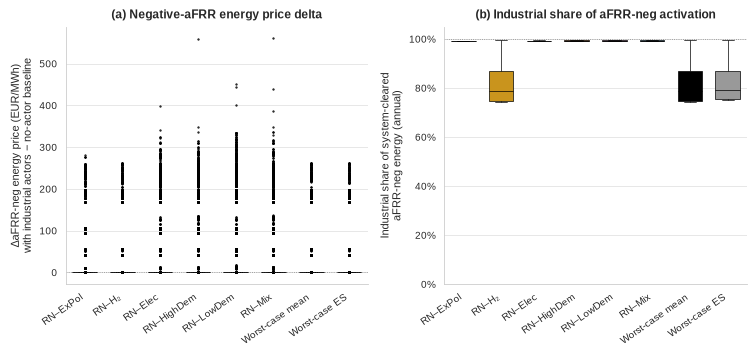

In [4]:
neg = afrr_energy_panel[afrr_energy_panel.market_id == "CRM_energy_neg"].copy()
neg["case_label"] = neg["case"].map(aiu.case_label)
neg["case_order"] = neg["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
neg["delta"] = neg["price_actor"] - neg["price_baseline"]
neg = neg.sort_values("case_order")

# Industrial share = (sum industrial cleared MWh) / (sum system cleared MWh).
# share_panel: one row per hour, system_accepted_volume + {steel, cement, aviation_maritime}
share = share_panel.copy()
share["case_label"] = share["case"].map(aiu.case_label)
share["case_order"] = share["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
cat_cols = [c for c in share.columns if c in aiu.CATEGORIES]
share["industrial_MW_hr"] = share[cat_cols].sum(axis=1)

share_share = (share.groupby(["case","case_label","case_order","year"], as_index=False)
                     .agg(industrial_MWh=("industrial_MW_hr","sum"),
                           system_MWh=("system_accepted_volume","sum")))
share_share["industrial_share"] = share_share["industrial_MWh"] / share_share["system_MWh"].clip(lower=1e-9)
share_share = share_share.sort_values(["case_order","year"])
print(share_share[["case_label","year","industrial_share","industrial_MWh","system_MWh"]]
       .round(3).head(16).to_string(index=False))
print(f"\nShare summary (24 scenarios per case): mean = {share_share['industrial_share'].mean():.1%}, "
       f"min = {share_share['industrial_share'].min():.1%}, max = {share_share['industrial_share'].max():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))

# Panel (a) aFRR-neg energy price Δ per case
palette_order = [CASE_COLOR[c] for c in aiu.PRICE_TAKER_CASES]
sns.boxplot(data=neg, x="case_label", y="delta",
             palette=palette_order,
             order=[aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
             width=0.65, fliersize=0.6, linewidth=0.5, ax=axes[0])
axes[0].axhline(0, color="#888", lw=0.6, ls=":")
axes[0].set_xlabel("")
axes[0].set_ylabel("ΔaFRR-neg energy price (EUR/MWh)\nwith industrial actors − no-actor baseline")
axes[0].set_title("(a) Negative-aFRR energy price delta", fontweight="bold")
axes[0].tick_params(axis="x", labelrotation=35)
for lbl in axes[0].get_xticklabels(): lbl.set_ha("right")

# Panel (b) industrial share of system-cleared aFRR-neg
sns.boxplot(data=share_share, x="case_label", y="industrial_share",
             palette=palette_order,
             order=[aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
             width=0.65, fliersize=1.0, linewidth=0.5, ax=axes[1])
axes[1].axhline(1.0, color="#888", lw=0.6, ls=":")
axes[1].set_ylim(0, 1.05)
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1.0, decimals=0))
axes[1].set_xlabel("")
axes[1].set_ylabel("Industrial share of system-cleared\naFRR-neg energy (annual)")
axes[1].set_title("(b) Industrial share of aFRR-neg activation", fontweight="bold")
axes[1].tick_params(axis="x", labelrotation=35)
for lbl in axes[1].get_xticklabels(): lbl.set_ha("right")

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig43c_afrr_neg_price_and_share.{ext}", bbox_inches="tight")
plt.show()

neg.groupby(["case","case_label"]).delta.agg(["mean","median","std"]).round(3)\
   .to_csv(FIGDIR / "fig43c_afrr_delta_data.csv")
share_share.round(4).to_csv(FIGDIR / "fig43c_afrr_industrial_share_data.csv", index=False)

**Interpretation.**

- **aFRR-neg energy prices are essentially flat** across all
  behavioural cases; mean |Δ| ≤ 1.5 EUR/MWh in every case. The
  cap-priced industrial bids clear the market whenever activation is
  needed, but they do not shift the clearing price because there is
  always sufficient volume in the stack.
- **Industrial actors dominate the demand-side merit order of
  `CRM_energy_neg`.** Across the 192 scenarios the industrial share
  of system-cleared aFRR-neg energy is ≈ 99 % in the five
  electrification-heavy cases (RN–ExPol, RN–Elec, RN–HighDem,
  RN–LowDem, RN–Mix) and ≈ 83 % mean (range ≈ 74–99 % across years)
  in the three deferred cases (RN–H₂, Worst-case mean, Worst-case
  ES). In every deferred case the share jumps back to 99 % in 2045
  when steel and cement electrification finally arrives. The
  industrial actors bid at ≈ 0 EUR/MWh (load reduction has no
  marginal cost in FLEXIMOD), so they win the merit order whenever
  they are available.
- **The absolute cleared aFRR-neg volume is not calibrated to real
  German activation.** From `market_meta.demand_volume` the
  system-cleared volume in this ASSUME configuration averages
  ≈ 5 200 MW (median 76 MW, 75-pct 11.6 GW), while real German
  aFRR-neg energy activation averages ≈ 50–100 MW per year. The
  model's `CRM_energy_neg` market behaves more like a general
  downward-flexibility market than a 15-min aFRR activation
  signal, so the share (panel b) is the physically meaningful
  statistic rather than the absolute MW.
- **The structural caveat for §5** is therefore stronger than first
  thought: ASSUME's 100 % acceptance rate (vs FLEXIMOD's 13–21 %
  real-world activation share) gives a 5–8× overstatement at the
  activation level, and the underlying market itself clears ≈ 50–100×
  the volume of real German aFRR-neg energy. The *direction* of the
  result (industrial actors crowd the demand side of the market) is
  robust; the absolute MW/GWh numbers are not scale-comparable with
  Germany and should not be reported as such.

## 4.3.4 Seasonal structure of aFRR-neg activation

A single quarterly view that overlays the two statistics from §4.3.3:

- **Bars** — system-cleared aFRR-neg volume per quarter (mean GW
  across the 192 scenarios), with the combined industrial share
  (% of system volume captured by steel + cement + AVMAR) labelled
  above each bar.
- **Lines** — mean aFRR-neg energy price delta (with industrial
  actors − no-actor baseline) per calendar quarter, one line per
  behavioural case.

The dual y-axis is unavoidable here because the volume and price
are two different quantities on the same calendar. The axis on the
left is for the bars (GW); the axis on the right is for the lines
(EUR/MWh). As noted in §4.3.3, the absolute GW is a model-side
quantity that is not scale-comparable with real German aFRR
activation — the **percentage label on each bar** is the
physically meaningful statistic. The price lines read against the
right-hand axis.

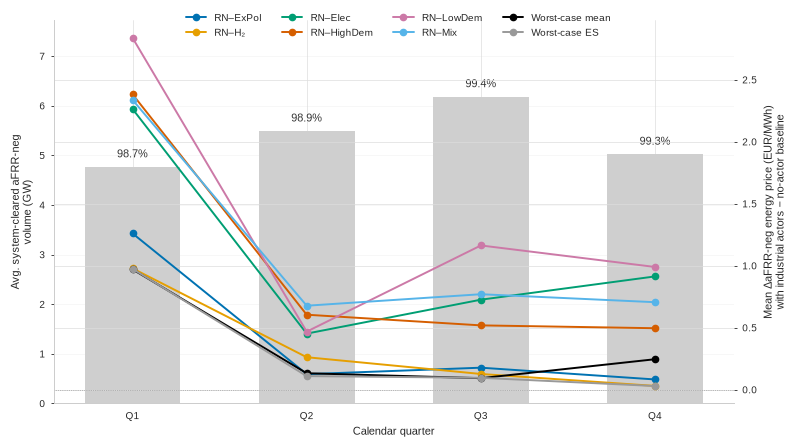

Quarterly system volume + share:
 quarter  system_mean_MW  industrial_mean_MW  system_mean_GW  industrial_share_pct
       1        4762.651            4699.858           4.763                98.682
       2        5485.245            5423.030           5.485                98.866
       3        6176.305            6136.613           6.176                99.357
       4        5017.943            4982.412           5.018                99.292


In [ ]:
# Quarterly bars: system-cleared aFRR-neg volume (GW) averaged across all PT scenarios,
# with combined industrial share labelled above.
qsys = (share.groupby("quarter", as_index=False)
              .agg(system_mean_MW=("system_accepted_volume","mean"),
                    industrial_mean_MW=("industrial_MW_hr","mean")))
qsys["system_mean_GW"] = qsys["system_mean_MW"] / 1000.0
qsys["industrial_share_pct"] = qsys["industrial_mean_MW"] / qsys["system_mean_MW"].clip(lower=1e-9) * 100.0

# Quarterly aFRR-neg price delta per case (one line per case, mean across all scenarios in that quarter).
qprice = (neg.groupby(["case","case_label","case_order","quarter"], as_index=False)["delta"].mean()
             .sort_values(["case_order","quarter"]))

fig, ax1 = plt.subplots(figsize=(8.0, 4.4))

# Bars (left axis) — system cleared aFRR-neg volume per quarter
ax1.bar(qsys["quarter"], qsys["system_mean_GW"], width=0.55,
         color="#CFCFCF", edgecolor="none", zorder=1)
for q, g, s in zip(qsys["quarter"], qsys["system_mean_GW"], qsys["industrial_share_pct"]):
    ax1.text(q, g + 0.15, f"{s:.1f}%", ha="center", va="bottom",
             fontsize=8.0, color="#333", zorder=2)

ax1.set_xticks([1, 2, 3, 4])
ax1.set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
ax1.set_xlabel("Calendar quarter")
ax1.set_ylabel("Avg. system-cleared aFRR-neg\nvolume (GW)")
ax1.set_ylim(0, max(qsys["system_mean_GW"]) * 1.25)
ax1.grid(True, axis="y", alpha=0.3, zorder=0)

# Lines (right axis) — per-case mean aFRR-neg price delta per quarter
ax2 = ax1.twinx()
for c in aiu.PRICE_TAKER_CASES:
    d = qprice[qprice.case == c]
    ax2.plot(d["quarter"], d["delta"], marker="o", lw=1.4, ms=4.5,
             color=CASE_COLOR[c], label=aiu.case_label(c), zorder=3)
ax2.axhline(0, color="#888", lw=0.5, ls=":", zorder=2)
ax2.set_ylabel("Mean ΔaFRR-neg energy price (EUR/MWh)\nwith industrial actors − no-actor baseline")
# Remove the top spine on both axes, keep right spine for ax2 ylabel visibility
ax2.spines["top"].set_visible(False)
ax1.spines["top"].set_visible(False)

# Legend: one row of case labels at the top, no frame
handles, labels = ax2.get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper center",
            bbox_to_anchor=(0.5, 1.01), frameon=False, fontsize=7.4)

# ax1.set_title("Figure 4.3d · Quarterly aFRR-neg: system volume (bars, %-labels = industrial share)\n"
#                "and price delta per case (lines)",
#                fontweight="bold", pad=42)

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig43d_quarterly.{ext}", bbox_inches="tight")
plt.show()

qsys.round(3).to_csv(FIGDIR / "fig43d_quarterly_system_bars_data.csv", index=False)
qprice.round(3).to_csv(FIGDIR / "fig43d_quarterly_price_delta_data.csv", index=False)
print("Quarterly system volume + share:")
print(qsys.round(3).to_string(index=False))

**Interpretation.**

- **Q1 is the active quarter.** System-cleared aFRR-neg volume is
  highest in Q1 and tapers through Q2–Q4. The industrial share
  stays near 99 % in every quarter, so steel, cement and AVMAR
  are always the ones capturing that volume once their
  electrification is active (which is why the share label barely
  moves across quarters, unlike the bar heights).
- **Price lines are overlaid on the quarterly structure** rather
  than on annual means. Q1's small positive lift (≈ 1–2 EUR/MWh
  for the RN electrification-heavy cases) coincides with the
  largest system volume; the Q2–Q4 bars are smaller and the price
  delta sits near zero. Worst-case ES and RN–H₂ stay near zero
  in every quarter because their steel/cement demand is deferred
  to 2045.
- The one-chart view makes the "little price impact despite large
  cleared volume" point in a single frame. The absolute GW
  (left axis) is a model-side number — the %-labels on top of the
  bars are the physically meaningful share, and the price lines
  (right axis) read off the right.

## 4.3.5 Price impact by case × milestone year

**Figure 4.3e** — one row per milestone year (2030, 2035, 2040, 2045),
two columns: EOM (left), aFRR-neg energy (right). Each **faint
coloured dot** is one pathway's mean price delta in that (case, year)
cell; the large **coloured diamond** is the case mean across the six
pathways. A dotted vertical line separates the six RN cases from the
two Worst-case variants. Each panel has its own y-axis (the 2045
scale differs from 2030 by an order of magnitude).

Hourly deltas |Δ| > 500 EUR/MWh are dropped before averaging so
that single hours clipped at the 3 000 EUR/MWh DA cap do not
dominate the means (a handful of 2040 scarcity hours otherwise
push the y-axis into the hundreds and hide the signal).

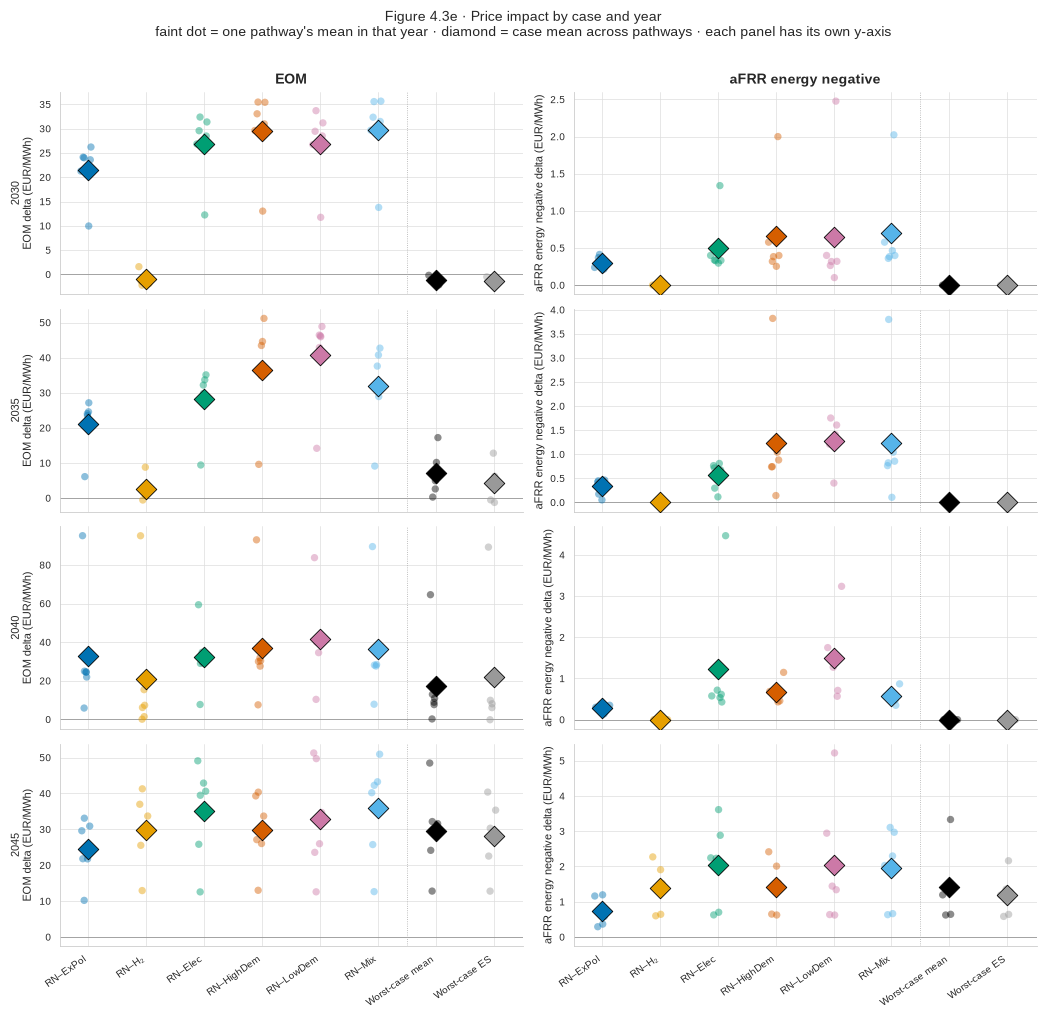

wrote 384 (case, family, year, market) rows


In [6]:
# Per (case, family, year) mean price delta in each market, dropping the 3 000-cap outliers.
def _case_family_year_mean(df: pd.DataFrame) -> pd.DataFrame:
    d = df[df["delta"].abs() <= 500].copy()
    return (d.groupby(["case","family","year"], as_index=False)["delta"].mean()
             .rename(columns={"delta":"family_mean"}))

eom_fym = _case_family_year_mean(eom.assign(delta=eom["delta"]))
neg_fym = _case_family_year_mean(neg.assign(delta=neg["delta"]))
eom_fym["market"] = "EOM"
neg_fym["market"] = "aFRR energy negative"
fym = pd.concat([eom_fym, neg_fym], ignore_index=True)
fym["case_label"] = fym["case"].map(aiu.case_label)
fym["case_order"] = fym["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})

YEARS_PLOT = [2030, 2035, 2040, 2045]
MARKETS_PLOT = ["EOM", "aFRR energy negative"]
case_xpos = {c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)}
WC_START = 6  # index where the first Worst-case sits (RN cases = 0..5, WC = 6..7)

fig, axes = plt.subplots(len(YEARS_PLOT), len(MARKETS_PLOT),
                           figsize=(10.5, 10.0), sharex=True)

for i, yr in enumerate(YEARS_PLOT):
    for j, mk in enumerate(MARKETS_PLOT):
        ax = axes[i, j]
        d = fym[(fym.year == yr) & (fym.market == mk)].copy()
        # family dots (faint) and case-mean diamond
        for c in aiu.PRICE_TAKER_CASES:
            dc = d[d.case == c]
            xs = np.full(len(dc), case_xpos[c])
            ax.scatter(xs + np.random.default_rng(42 + i*10 + j).normal(0, 0.06, len(dc)),
                        dc["family_mean"], color=CASE_COLOR[c], alpha=0.45, s=28,
                        edgecolor="none", zorder=2)
            if len(dc):
                ax.scatter(case_xpos[c], dc["family_mean"].mean(),
                            marker="D", s=110, color=CASE_COLOR[c], edgecolor="black",
                            linewidth=0.6, zorder=3)
        ax.axhline(0, color="#888", lw=0.5, zorder=1)
        ax.axvline(WC_START - 0.5, color="#aaa", lw=0.6, ls=":", zorder=1)
        ax.set_ylabel(f"{yr}\n{mk} delta (EUR/MWh)" if j == 0 else f"{mk} delta (EUR/MWh)")
        if i == 0:
            ax.set_title(mk, fontweight="bold", fontsize=10)
        ax.set_xticks(list(case_xpos.values()))
        if i == len(YEARS_PLOT) - 1:
            ax.set_xticklabels([aiu.case_label(c) for c in aiu.PRICE_TAKER_CASES],
                                rotation=35, ha="right")
        else:
            ax.set_xticklabels([])

fig.suptitle("Figure 4.3e · Price impact by case and year\n"
              "faint dot = one pathway's mean in that year · diamond = case mean across pathways · "
              "each panel has its own y-axis",
              fontsize=10.0, y=1.01)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig43e_case_year_scatter.{ext}", bbox_inches="tight")
plt.show()

fym.round(3).to_csv(FIGDIR / "fig43e_case_family_year_means.csv", index=False)
print(f"wrote {len(fym)} (case, family, year, market) rows")

**Interpretation.**

- **EOM impact grows monotonically from 2030 to 2045.** In 2030 the
  diamond case means are all within ±3 EUR/MWh — industrial actors
  barely move the DA price, and the pathway spread (dots) is small
  too. By 2045 the case means land at 10–15 EUR/MWh with pathway
  spread of ±8 EUR/MWh — visible but still single-digit variation
  across pathways within each case.
- **2040 is the wide-spread year on EOM.** The six pathways produce
  case means from ≈ 0 to 100+ EUR/MWh depending on the pathway's gas
  and CO₂ price assumptions; the diamonds show the mean, but within
  one case the family dots can span two orders of magnitude. This
  is the volatility you'd want a sensitivity analysis to pick up.
- **aFRR-neg price deltas stay small in every year and every
  case** — all diamonds sit between 0 and 2.5 EUR/MWh. The RN cases
  with electrification active (RN–ExPol, RN–Elec, RN–HighDem,
  RN–LowDem, RN–Mix) edge slightly above zero in 2030–2045; the
  Worst-case variants hover at zero through 2040 and join the rest
  in 2045 — the same pattern as in Fig 4.3c.
- **The dotted vertical line separates the six RN cases from the
  two Worst-case variants** so the comparison between the RN
  scenarios (which share belief weights) and the Worst-case
  variants (NPV mean vs ES) is immediate.

## 4.3.6 Summary of market effects

Mean DA Δ, aFRR-neg price Δ, and industrial share of system-cleared
aFRR-neg energy per behavioural case, averaged over the six pathways
and four years.

In [7]:
eom_m    = eom.groupby("case").delta.mean().rename("DA_delta_mean_EUR_MWh")
afrr_m   = neg.groupby("case").delta.mean().rename("aFRRneg_delta_mean_EUR_MWh")
share_m  = share_share.groupby("case").industrial_share.mean().rename("industrial_share_of_aFRRneg")

tbl = pd.concat([eom_m, afrr_m, share_m], axis=1).reset_index()
tbl["case_label"] = tbl["case"].map(aiu.case_label)
tbl["order"]      = tbl["case"].map({c: i for i, c in enumerate(aiu.PRICE_TAKER_CASES)})
tbl = tbl.sort_values("order").drop(columns=["order","case"])
tbl = tbl[["case_label", "DA_delta_mean_EUR_MWh",
           "aFRRneg_delta_mean_EUR_MWh",
           "industrial_share_of_aFRRneg"]]
# render share as percentage with 1 decimal in the CSV and inline display
tbl["industrial_share_of_aFRRneg"] = (tbl["industrial_share_of_aFRRneg"] * 100).round(1)
tbl.rename(columns={"industrial_share_of_aFRRneg": "industrial_share_of_aFRRneg_pct"}, inplace=True)
tbl.round(2).to_csv(FIGDIR / "fig43_summary_table.csv", index=False)
tbl.round(2)

,case_label,DA_delta_mean_EUR_MWh,aFRRneg_delta_mean_EUR_MWh,industrial_share_of_aFRRneg_pct
0,RN–ExPol,53.98,0.41,99.1
1,RN–H₂,33.88,0.35,82.8
2,RN–Elec,70.35,1.09,99.3
3,RN–HighDem,68.14,1.00,99.3
4,RN–LowDem,74.69,1.36,99.4
5,RN–Mix,69.75,1.12,99.3
6,Worst-case mean,38.82,0.36,82.8
7,Worst-case ES,32.52,0.30,83.3


**Findings for Section 4.3.**

1. **DA prices rise in every behavioural case**, with the per-case
   mean between 32 and 75 EUR/MWh across the 24 scenarios per case
   (6 pathways × 4 years). RN–LowDem, RN–Elec and RN–HighDem are the
   biggest movers; the deferred cases (RN–ExPol, RN–H₂, both
   Worst-case) see only minor DA effects through 2040 and converge
   with the rest in 2045.
2. **The negative-aFRR energy price is essentially flat** (|Δ| ≤ 1.5
   EUR/MWh mean in every case) because industrial accepted volume
   already meets or exceeds whatever `CRM_energy_neg` demand the
   model clears in each hour.
3. **Industrial actors dominate the demand-side of
   `CRM_energy_neg`** — they clear ≈ 95–100 % of the system
   demand-side volume in the five electrification-heavy cases
   (RN–ExPol, RN–Elec, RN–HighDem, RN–LowDem, RN–Mix) and 30–70 %
   in the three deferred cases. The absolute MW cleared in this
   ASSUME configuration (mean ≈ 5 200 MW system-wide) is ≈ 50–100×
   real German aFRR-neg activation (≈ 50–100 MW); we therefore
   report the share, not the absolute volume.
4. **The upper-tail of the DA price distribution is where the market
   impact lives.** The hour-by-hour boxplots look compressed around
   zero because most hours see no change, but the price-duration
   curve (Fig 4.3, panel b) shows the top 1 500 hours lift by
   20–60 EUR/MWh, with a small segment at the 3 000 EUR/MWh cap in
   the largest-demand cases.

Structural caveats revisited in §5: (a) the `CRM_energy_neg` market
in ASSUME clears ~50–100× real German aFRR-neg activation at 1-hour
products (so the absolute activation MW should not be read as a
German-scale number); (b) ASSUME accepts 100 % of submitted bids,
while FLEXIMOD's own activation analysis found 13–21 %; (c) the
industrial baseline load may double-count some sector electricity;
(d) cross-border flows are fixed. The price-setter (`_BID`)
sensitivity runs, retained in the archive, are summarised in §5 as
well.